# Huấn Luyện Mạng U-Net Chuẩn (Ronneberger et al., 2015)
Notebook điều khiển toàn bộ pipeline: Kiểm tra GPU -> Cài đặt thư viện -> Huấn luyện -> Đánh giá -> Suy luận.

In [1]:
# 1. Kiểm tra thông số GPU trên Colab
!nvidia-smi

Fri Oct 23 12:14:14 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2. Mount Google Drive để lưu trữ mã nguồn và checkpoints
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# 3. Trỏ tới thư mục unet_baseline trên Drive và kiểm tra tệp tin
import os
import sys

# ĐƯỜNG DẪN DỰ ÁN TRÊN GOOGLE DRIVE (điều chỉnh nếu bạn lưu ở thư mục khác)
WORKSPACE_DIR = '/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/unet_baseline'

os.chdir(WORKSPACE_DIR)
print('Thư mục hiện tại:', os.getcwd())
!ls -lh

Thư mục hiện tại: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/unet_baseline
total 1.4M
-rw------- 1 root root 2.6K Oct 23 02:13 check_native_pipeline.py
drwx------ 2 root root 4.0K Oct 10 07:18 checkpoints
-rw------- 1 root root 125K Oct 21 15:45 codebase_context.txt
drwx------ 2 root root 4.0K Oct 10 07:18 configs
drwx------ 2 root root 4.0K Oct 10 07:18 data
-rw------- 1 root root  13K Oct 22 18:24 diagnose.py
drwx------ 2 root root 4.0K Oct 10 07:16 docs
-rw------- 1 root root  15K Oct 22 18:24 evaluate.py
drwx------ 2 root root 4.0K Oct 10 19:19 evaluation_results
-rw------- 1 root root  14K Oct 21 15:44 export_codebase.py
drwx------ 2 root root 4.0K Oct 10 07:18 models
drwx------ 2 root root 4.0K Oct 19 18:59 predictions
-rw------- 1 root root  11K Oct 23 09:42 predict.py
-rw------- 1 root root 250K Oct 21 15:58 prompt_for_ai.txt
drwx------ 2 root root 4.0K Oct 20 17:26 __pycache__
-rw------- 1 root root 5.1K Oct 10 07:24 README.md
-rw------- 1 root

In [4]:
# 4. Cài đặt các thư viện cần thiết
!pip install -r requirements.txt -q

In [5]:
# 6. QUẢN LÝ DỮ LIỆU: Nén Linux CÓ THANH QUÁ TRÌNH -> Lưu Drive -> Giải nén vào SSD
# =================================================================================
import os
import time
import subprocess
from pathlib import Path
from tqdm import tqdm

# 1. Khai báo các đường dẫn
DRIVE_DATA_DIR = Path("/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data")
DRIVE_ZIP = DRIVE_DATA_DIR / "segmented_slices.zip"
COLAB_ZIP = Path("/content/segmented_slices.zip")
TARGET_DIR = Path("/content/segmented_slices")

# 2. BƯỚC 1: Nếu chưa có file zip -> Nén nguyên khối kèm THANH TIẾN TRÌNH
if not DRIVE_ZIP.exists() and not COLAB_ZIP.exists():
    print("📦 Đang đóng gói 26,000 files từ Google Drive (khoảng 8-10 phút)...")
    t0 = time.time()

    # Chạy zip trực tiếp từ Linux và bắt luồng output để vẽ thanh tiến trình
    cmd = f'cd "{DRIVE_DATA_DIR}" && zip -0 -r /content/segmented_slices.zip segmented_slices'
    proc = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)

    with tqdm(total=26100, desc="🚀 Đang đóng gói zip", unit=" file") as pbar:
        for line in proc.stdout:
            if "adding:" in line:
                pbar.update(1)
        if pbar.n < pbar.total:
            pbar.n = pbar.total
            pbar.refresh()

    proc.wait()
    if proc.returncode != 0:
        raise RuntimeError("❌ Có lỗi xảy ra trong quá trình nén zip!")

    print(f"\n⚡ Đã đóng gói xong ({COLAB_ZIP.stat().st_size / (1024*1024):.1f} MB) trong {time.time()-t0:.1f}s.")

    print("💾 Đang sao lưu file zip vào Google Drive để vĩnh viễn không phải nén lại...")
    !cp /content/segmented_slices.zip "{DRIVE_ZIP}"
    print("✅ Đã lưu file zip an toàn trên Google Drive!")

elif DRIVE_ZIP.exists() and not COLAB_ZIP.exists():
    print("✅ Đã tìm thấy file zip có sẵn trên Google Drive!")
    COLAB_ZIP = DRIVE_ZIP

# 3. BƯỚC 2: Giải nén toàn bộ dữ liệu vào SSD nội bộ của Colab (/content/segmented_slices)
print("\n🚀 Đang giải nén toàn bộ dữ liệu vào SSD Colab...")
t_unzip = time.time()
!unzip -q -o "{COLAB_ZIP}" -d /content/
print(f"⚡ Giải nén hoàn tất trong {time.time()-t_unzip:.1f} giây!")

# 4. BƯỚC 3: Kiểm tra tính sẵn sàng của toàn bộ dữ liệu trên SSD
print("\n🎉 DỮ LIỆU ĐÃ SẴN SÀNG TRÊN SSD COLAB:")
for split in ['train', 'val', 'test']:
    n_img = len(os.listdir(TARGET_DIR / split / "images")) if (TARGET_DIR / split / "images").exists() else 0
    n_msk = len(os.listdir(TARGET_DIR / split / "masks")) if (TARGET_DIR / split / "masks").exists() else 0
    print(f"   [{split.upper():5s}] Ảnh: {n_img:4d} | Mask: {n_msk:4d}")

✅ Đã tìm thấy file zip có sẵn trên Google Drive!

🚀 Đang giải nén toàn bộ dữ liệu vào SSD Colab...
⚡ Giải nén hoàn tất trong 80.4 giây!

🎉 DỮ LIỆU ĐÃ SẴN SÀNG TRÊN SSD COLAB:
   [TRAIN] Ảnh: 9344 | Mask: 9344
   [VAL  ] Ảnh: 1700 | Mask: 1700
   [TEST ] Ảnh: 2007 | Mask: 2007


In [6]:
!python check_native_pipeline.py --config configs/config_native.yaml --data.root_dir=/content/segmented_slices

  ⚡ [TRAIN] Đã giới hạn mẫu thử nghiệm: 256 mẫu.
  ⚡ [VAL] Đã giới hạn mẫu thử nghiệm: 64 mẫu.
  ⚡ [TEST] Đã giới hạn mẫu thử nghiệm: 64 mẫu.
Cảnh báo tham số không hợp lệ: không có
[train] images (16, 3, 192, 192) masks (16, 1, 192, 192) | mask unique [0.0, 1.0]
[train] tỉ lệ crop có nốt trong batch: 0.75 (kỳ vọng ~0.7–0.85)
[val] các kích thước batch (đã pad bội số 32): [(480, 480), (512, 512), (576, 576), (640, 640)]
[fwd/bwd] out (16, 1, 192, 192) loss 0.8230  -> OK


In [ ]:
# Copy dữ liệu sang SSD nội bộ của máy chủ Colab
# !cp -r "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/segmented_slices" /content/segmented_slices

In [7]:
# 7. Bắt đầu quá trình huấn luyện U-Net Baseline
# =====================================================================
# CÁCH 1 (Khuyên dùng): Huấn luyện TOÀN BỘ 9,343 mẫu (Full Dataset, 50 Epochs, batch_size=16):
!python train.py --config configs/config.yaml \
                 --data.root_dir=/content/segmented_slices \
                 --checkpoint.dir=/content/ckpt --logging.log_dir=/content/runs \
                 --train.epochs=50 --train.batch_size=16 --train.num_workers=2

# CÁCH 2 (Thử nghiệm nhanh): Huấn luyện với số lượng mẫu giới hạn (5000 mẫu train, 35 epochs):
# !python train.py --config configs/config.yaml \
#                  --data.root_dir=/content/segmented_slices \
#                  --train.limit_train_samples=5000 \
#                  --train.limit_val_samples=500 \
#                  --train.limit_test_samples=500 \
#                  --train.epochs=35 --train.batch_size=16 --train.num_workers=2


I0000 00:00:1792757923.401375    2123 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792757928.007095    2123 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
🚀 Sử dụng thiết bị: cuda
📦 Đang nạp dữ liệu...
  - Train samples : 9343 (583 batches)
  - Val samples   : 1699 (107 batches)
  - Test samples  : 2006 (126 batches)
⚡ Đã bật tối ưu hóa memory_format=torch.channels_last cho GPU

🚀 Bắt đầu huấn luyện 50 Epochs...
Epoch [001/050] | Train Loss: 0.5552 | Val Loss: 0.4017 | Val Dice: 0.3368 | Val IoU: 0.2693 | Time: 4m 10s | LR: 0.000500
  🌟 Lưu mô hình tốt nhất (best.pth) tại Epoch 001 (val_dice: 0.3368)
Epoch [002/050] | Train Loss: 0.3538 | Val Loss: 0.3359 | Val Dice: 0.4486 | Val IoU: 0.3552 | Time: 4m 11s | LR: 0.0005

In [8]:
!cp /content/ckpt/best.pth /content/ckpt/last.pth "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/unet_baseline/checkpoints/"

In [12]:
# 7. RESUME huấn luyện (Chạy cell này nếu Colab bị ngắt kết nối giữa chừng)
# !python train.py --config configs/config.yaml --checkpoint.resume_path=checkpoints/last.pth
!python train.py --config configs/config_native.yaml \
                 --data.root_dir=/content/segmented_slices \
                 --checkpoint.dir=/content/ckpt --logging.log_dir=/content/runs \
                 --checkpoint.resume_path=/content/ckpt/last.pth

📊 TỔNG KẾT THỜI GIAN & HIỆU SUẤT HUẤN LUYỆN:
  ⏱️ Tổng thời gian chạy     : 2h 51m 25s (10285.54s)
  ⏱️ Thời gian TB / Epoch    : 3m 43s
  🌟 Epoch tốt nhất          : Epoch 31 (val_dice: 0.5851)


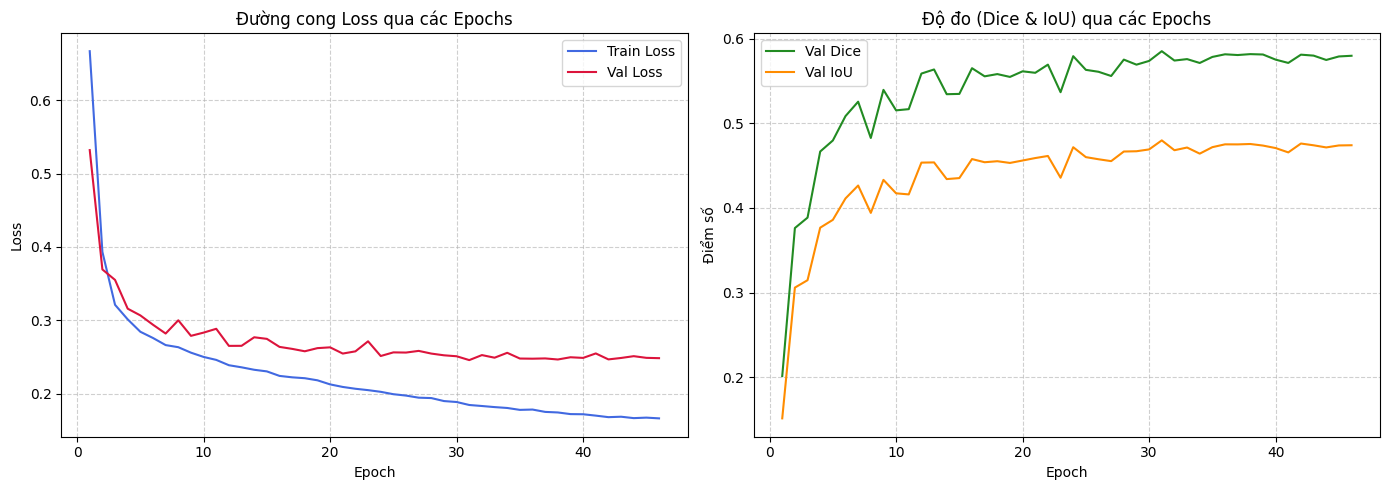

In [9]:
# 9. Trực quan hóa kết quả: Thời gian chạy, đường cong Loss và Metric
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# 1. In tóm tắt thời gian huấn luyện từ train_summary.json
summary_file = 'checkpoints/train_summary.json'
if os.path.exists(summary_file):
    with open(summary_file, 'r', encoding='utf-8') as f:
        s = json.load(f)
    print('=' * 60)
    print('📊 TỔNG KẾT THỜI GIAN & HIỆU SUẤT HUẤN LUYỆN:')
    print(f"  ⏱️ Tổng thời gian chạy     : {s.get('total_time_formatted')} ({s.get('total_time_sec')}s)")
    print(f"  ⏱️ Thời gian TB / Epoch    : {s.get('avg_epoch_time_formatted')}")
    print(f"  🌟 Epoch tốt nhất          : Epoch {s.get('best_epoch')} ({s.get('best_metric_name')}: {s.get('best_metric_value')})")
    print('=' * 60)

# 2. Vẽ biểu đồ Loss và Metric qua các Epochs
history_file = 'checkpoints/history.csv'
if os.path.exists(history_file):
    df = pd.read_csv(history_file)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(df['epoch'], df['train_loss'], label='Train Loss', color='royalblue')
    axes[0].plot(df['epoch'], df['val_loss'], label='Val Loss', color='crimson')
    axes[0].set_title('Đường cong Loss qua các Epochs')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    axes[1].plot(df['epoch'], df['val_dice'], label='Val Dice', color='forestgreen')
    axes[1].plot(df['epoch'], df['val_iou'], label='Val IoU', color='darkorange')
    axes[1].set_title('Độ đo (Dice & IoU) qua các Epochs')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Điểm số')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()
else:
    print('Chưa tìm thấy history.csv. Hãy huấn luyện ít nhất 1 epoch.')


In [11]:
# 9. Đánh giá chất lượng mô hình trên tập Test (Toàn bộ 2,006 mẫu (Dice, IoU, HD95))
# ==================================================================================
# !python evaluate.py --checkpoint checkpoints/best.pth \
#                     --config configs/config.yaml \
#                     --data.root_dir=/content/segmented_slices \
#                     --threshold=0.5 \
#                     --save_overlay
!python evaluate.py --checkpoint /content/ckpt/best.pth \
                    --config configs/config_native.yaml \
                    --data.root_dir=/content/segmented_slices \
                    --threshold=0.5

🔬 Đánh giá checkpoint: /content/ckpt/best.pth trên thiết bị: cuda
  ⚡ [VAL] Đã giới hạn mẫu thử nghiệm: 800 mẫu.
📊 Tổng số mẫu kiểm thử: 2006
⏳ Đang chạy suy luận trên tập Test...
[Evaluate]: 100% 126/126 [01:26<00:00,  1.45it/s]

📋 KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST:
  - Tổng số mẫu đánh giá : 2006
  - Dice Coefficient      : 0.1930 ± 0.2954
  - IoU (Jaccard)         : 0.1460 ± 0.2419
  - HD95 (Hausdorff)      : 136.3812 ± 81.3066 (Hợp lệ: 1663/2006, NaN: 343)
-----------------------------------------------------------------
📊 PHÂN TẦNG HIỆU NĂNG THEO DIỆN TÍCH NỐT U (GROUND TRUTH):
  Nhóm kích thước        | Số mẫu   | Dice (Mean ± Std)    | Dự đoán rỗng (sót)
  ---------------------------------------------------------------------------
  <=24 (rất nhỏ)         | 540      | 0.1371 ± 0.2330      | 103               
  25-57 (nhỏ)            | 511      | 0.2710 ± 0.3043      | 57                
  58-177 (trung bình)    | 510      | 0.2305 ± 0.3334      | 109               
  >177 (lớn)   

In [13]:
# 10. Suy luận dự đoán trên tập Test (Inference)
# =====================================================================
!python predict.py --input /content/segmented_slices/test/images \
                   --output predictions \
                   --checkpoint checkpoints/best.pth \
                   --limit 50


🔍 Tìm thấy 50 ảnh cần dự đoán (lấy mẫu ngẫu nhiên 50 ảnh trải qua nhiều bệnh nhân (seed=42)).
🚀 Đang tiến hành suy luận...
[Predict]: 100% 50/50 [01:28<00:00,  1.76s/it]

🎉 Dự đoán hoàn tất! Kết quả được lưu tại: predictions
  - Thư mục Masks    : predictions/masks
  - Thư mục Overlays : predictions/overlays


/tmp/ipykernel_600/2811508145.py:83: UserWarning: Glyph 129001 (\N{LARGE GREEN SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_600/2811508145.py:83: UserWarning: Glyph 128997 (\N{LARGE RED SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_600/2811508145.py:83: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129001 (\N{LARGE GREEN SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128997 (\N{LARGE RED SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print

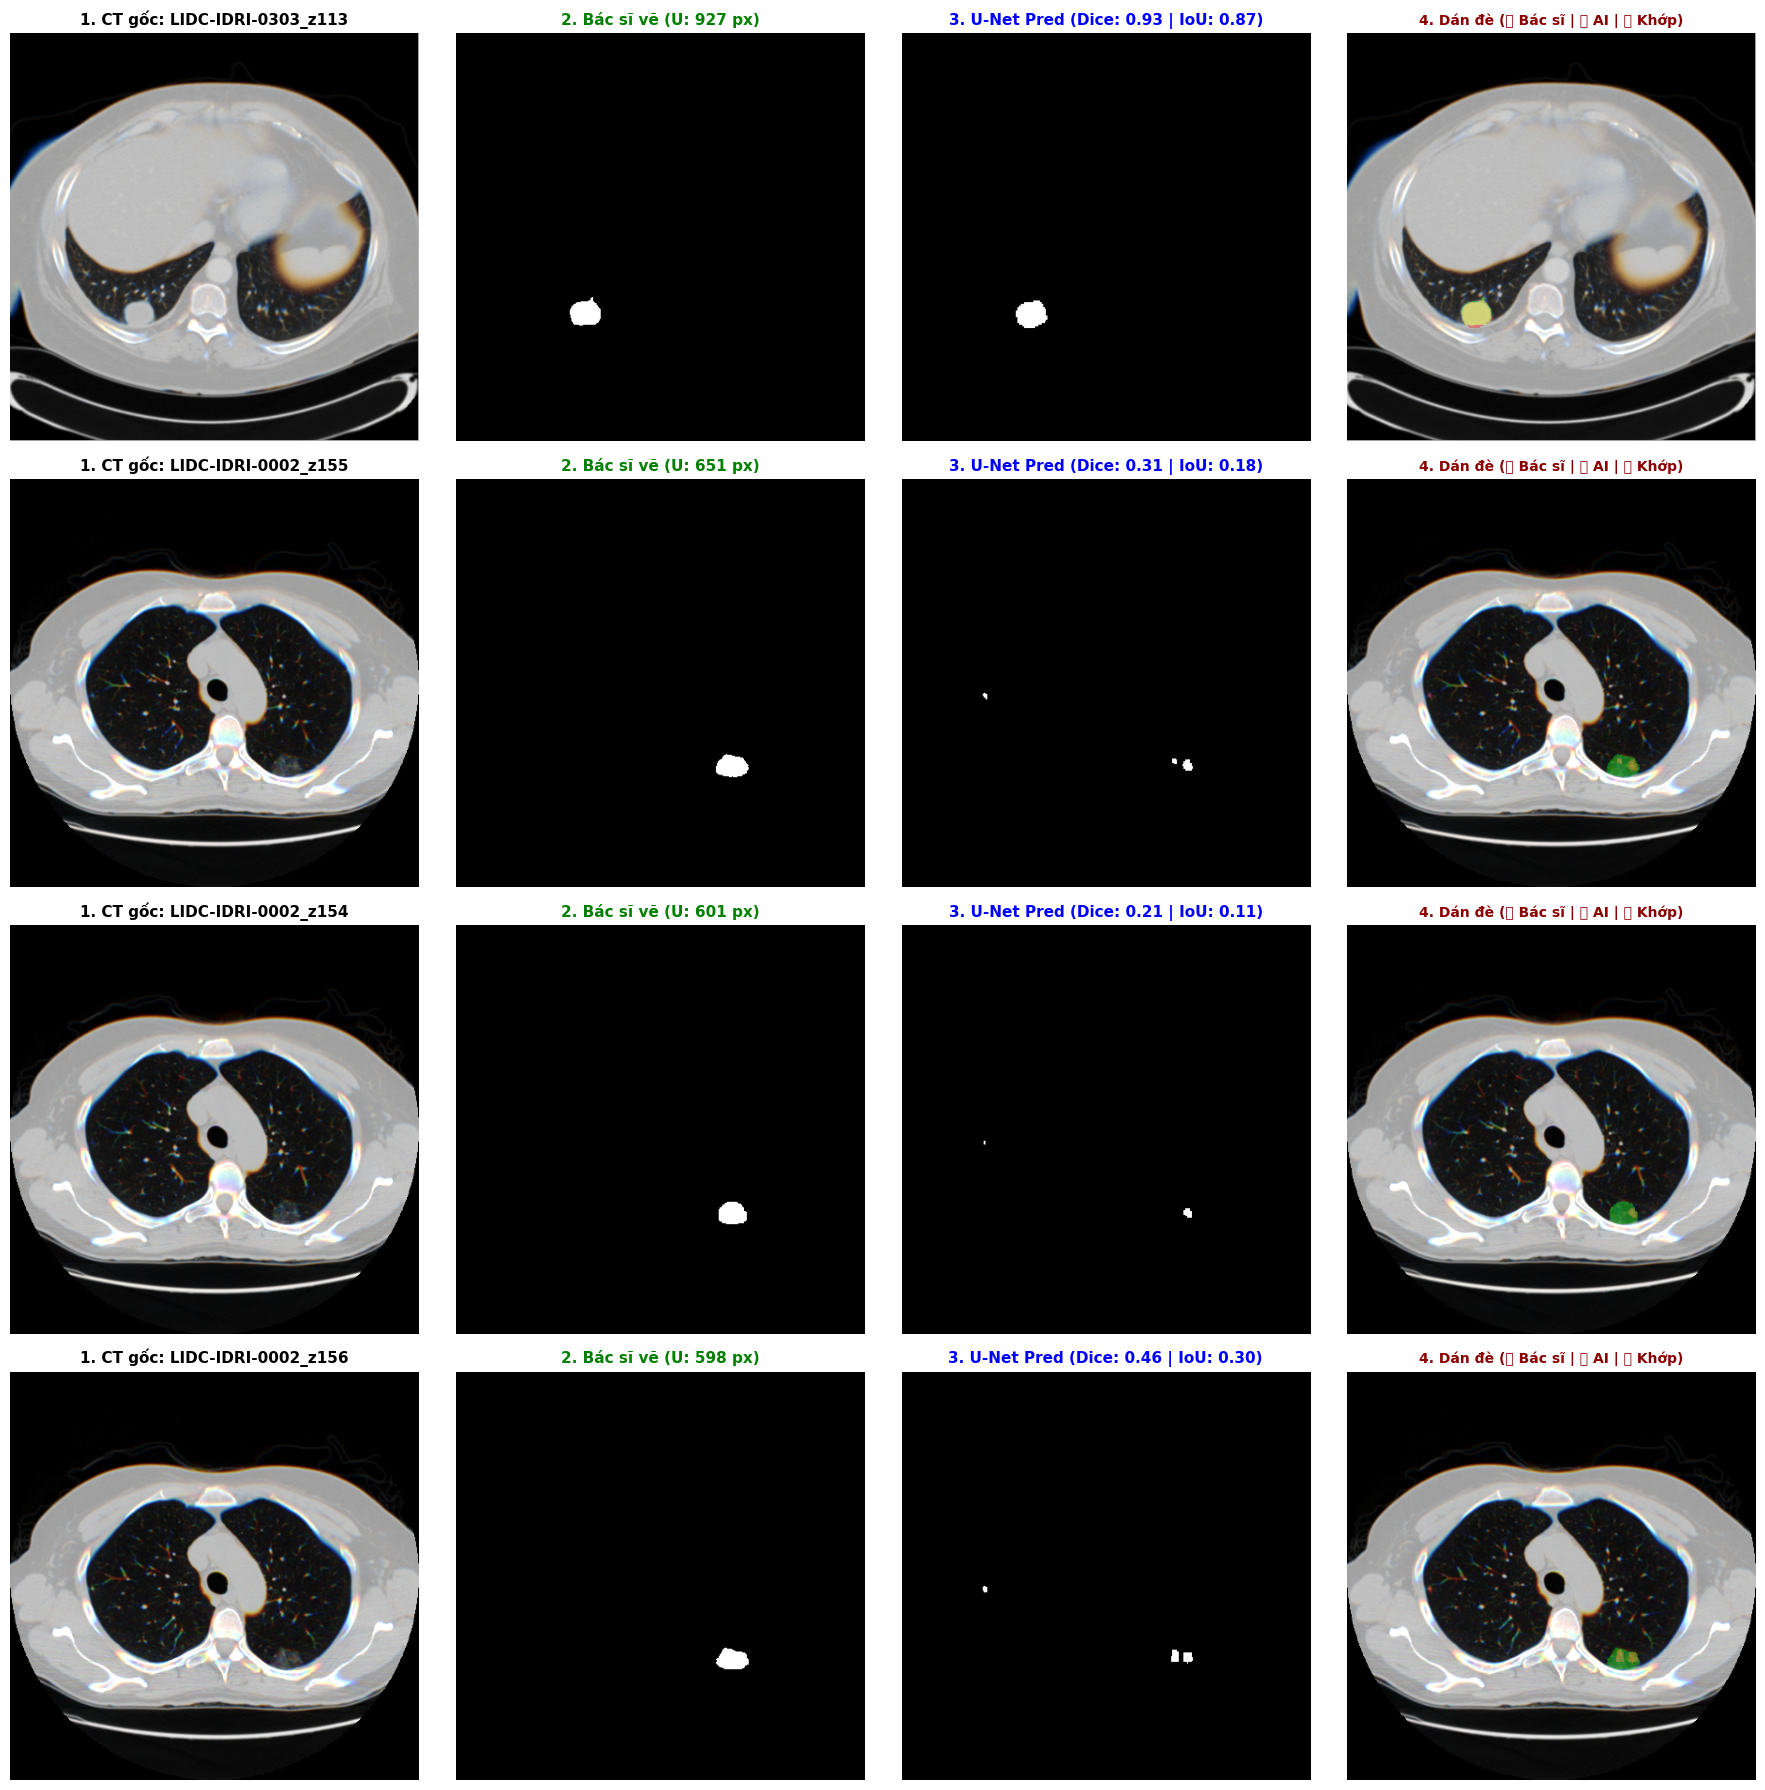

In [14]:
# 11. Trực quan hóa so sánh chuyên sâu (Lọc mẫu có U rõ -> 4 Cột: CT | Bác sĩ | AI | Dán đè)
# =========================================================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Tự động phát hiện thư mục dữ liệu trên SSD Colab
DATA_ROOT = Path('/content/segmented_slices') if Path('/content/segmented_slices').exists() else Path('/content/quick_data')
TEST_IMG_DIR = DATA_ROOT / 'test' / 'images'
TEST_MSK_DIR = DATA_ROOT / 'test' / 'masks'
PRED_MSK_DIR = Path('predictions/masks')

# 1. Lọc trong số các ảnh đã dự đoán những mẫu CÓ NỐT U RÕ RÀNG (diện tích u >= 30 pixels)
candidate_samples = []
pred_files = list(PRED_MSK_DIR.glob('*_mask.png')) if PRED_MSK_DIR.exists() else []

for pf in pred_files:
    stem = pf.stem.replace('_mask', '')
    gt_file = TEST_MSK_DIR / f'{stem}.png'
    if gt_file.exists():
        gt = cv2.imread(str(gt_file), cv2.IMREAD_GRAYSCALE)
        tumor_area = cv2.countNonZero(gt)
        if tumor_area >= 30:
            candidate_samples.append((stem, tumor_area))

candidate_samples.sort(key=lambda x: x[1], reverse=True)
selected_stems = [stem for stem, _ in candidate_samples[:4]]

if not selected_stems and pred_files:
    selected_stems = [pf.stem.replace('_mask', '') for pf in pred_files[:4]]

if not selected_stems:
    print('⚠️ Chưa có ảnh dự đoán nào trong predictions/masks/. Hãy chạy Cell 10 trước.')
else:
    n_samples = len(selected_stems)
    fig, axes = plt.subplots(n_samples, 4, figsize=(18, 4.5 * n_samples))
    if n_samples == 1:
        axes = [axes]

    for row, stem in enumerate(selected_stems):
        img_p = TEST_IMG_DIR / f'{stem}.png'
        gt_p  = TEST_MSK_DIR / f'{stem}.png'
        pr_p  = PRED_MSK_DIR / f'{stem}_mask.png'

        img = cv2.imread(str(img_p), cv2.IMREAD_COLOR)
        gt  = cv2.imread(str(gt_p), cv2.IMREAD_GRAYSCALE) if gt_p.exists() else np.zeros((256, 256), dtype=np.uint8)
        pr  = cv2.imread(str(pr_p), cv2.IMREAD_GRAYSCALE) if pr_p.exists() else np.zeros((256, 256), dtype=np.uint8)

        gt_mask = gt > 0
        pr_mask = pr > 0
        intersection = np.logical_and(gt_mask, pr_mask).sum()
        union = np.logical_or(gt_mask, pr_mask).sum()
        dice = (2.0 * intersection) / (gt_mask.sum() + pr_mask.sum() + 1e-6)
        iou = intersection / (union + 1e-6)

        overlay = img.copy() if img is not None else np.zeros((256, 256, 3), dtype=np.uint8)
        overlap_mask = np.logical_and(gt_mask, pr_mask)
        overlay[gt_mask] = [0, 255, 0]        # Xanh lá: Đáp án bác sĩ
        overlay[pr_mask] = [0, 0, 255]        # Đỏ: AI phân đoạn
        overlay[overlap_mask] = [0, 255, 255] # Vàng: Trùng khớp 100%

        blended = cv2.addWeighted(img, 0.65, overlay, 0.35, 0) if img is not None else overlay

        if img is not None:
            axes[row][0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[row][0].set_title(f'1. CT gốc: {stem}', fontsize=11, fontweight='bold')
        axes[row][0].axis('off')

        axes[row][1].imshow(gt, cmap='gray')
        axes[row][1].set_title(f'2. Bác sĩ vẽ (U: {gt_mask.sum()} px)', fontsize=11, color='green', fontweight='bold')
        axes[row][1].axis('off')

        axes[row][2].imshow(pr, cmap='gray')
        axes[row][2].set_title(f'3. U-Net Pred (Dice: {dice:.2f} | IoU: {iou:.2f})', fontsize=11, color='blue', fontweight='bold')
        axes[row][2].axis('off')

        axes[row][3].imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
        axes[row][3].set_title('4. Dán đè (🟩 Bác sĩ | 🟥 AI | 🟨 Khớp)', fontsize=10, color='darkred', fontweight='bold')
        axes[row][3].axis('off')

    plt.tight_layout()
    plt.show()
